In [1]:
import pandas as pd
import numpy as np

import seaborn as sns
import matplotlib.pyplot as plt
import missingno as msn

from collections import Counter
from matplotlib.colors import ListedColormap

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.preprocessing import MinMaxScaler,StandardScaler,RobustScaler,OneHotEncoder, KBinsDiscretizer, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold, GridSearchCV, RandomizedSearchCV
from sklearn.pipeline import Pipeline

from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression, LinearRegression, Lasso, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import VotingClassifier, RandomForestClassifier, AdaBoostClassifier, GradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from xgboost.sklearn import XGBClassifier

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report, f1_score, recall_score, precision_score, mean_squared_error, RocCurveDisplay, mean_absolute_percentage_error
from sklearn.metrics._scorer import _SCORERS

from sklearn.experimental import enable_iterative_imputer
from sklearn.impute import IterativeImputer, KNNImputer, SimpleImputer

import category_encoders as ce

import warnings
warnings.filterwarnings('ignore')

In [2]:
# import dataset
df_adult = pd.read_csv('Dataset/adult.csv')
df_adult

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32556,22,Private,310152,Some-college,10,Never-married,Protective-serv,Not-in-family,White,Male,0,0,40,United-States,<=50K
32557,27,Private,257302,Assoc-acdm,12,Married-civ-spouse,Tech-support,Wife,White,Female,0,0,38,United-States,<=50K
32558,40,Private,154374,HS-grad,9,Married-civ-spouse,Machine-op-inspct,Husband,White,Male,0,0,40,United-States,>50K
32559,58,Private,151910,HS-grad,9,Widowed,Adm-clerical,Unmarried,White,Female,0,0,40,United-States,<=50K


In [3]:
# elaborate using snipplet we've create before
# nullity and unique value
# check data nullity, unique value
pd.set_option('display.max_colwidth',None)
pd.DataFrame({
    'feature':df_adult.columns.values,
    'data_type':df_adult.dtypes.values,
    'null':df_adult.isna().mean().values * 100,
    'negative': [True if df_adult[i].dtype == int and (df_adult[i] < 0).any else False for i in df_adult.columns],
    'n_unique':df_adult.nunique().values,
    'sample_unique':[df_adult[i].unique() for i in df_adult.columns]
})

,feature,data_type,null,negative,n_unique,sample_unique
0,age,int64,0.0,False,73,"[90, 82, 66, 54, 41, 34, 38, 74, 68, 45, 52, 32, 51, 46, 57, 22, 37, 29, 61, 21, 33, 49, 23, 59, 60, 63, 53, 44, 43, 71, 48, 73, 67, 40, 50, 42, 39, 55, 47, 31, 58, 62, 36, 72, 78, 83, 26, 70, 27, 35, 81, 65, 25, 28, 56, 69, 20, 30, 24, 64, 75, 19, 77, 80, 18, 17, 76, 79, 88, 84, 85, 86, 87]"
1,workclass,object,0.0,False,9,"[?, Private, State-gov, Federal-gov, Self-emp-not-inc, Self-emp-inc, Local-gov, Without-pay, Never-worked]"
2,fnlwgt,int64,0.0,False,21648,"[77053, 132870, 186061, 140359, 264663, 216864, 150601, 88638, 422013, 70037, 172274, 164526, 129177, 136204, 172175, 45363, 172822, 317847, 119592, 203034, 188774, 77009, 29059, 153870, 135285, 34310, 228696, 122066, 107164, 175360, 44064, 107287, 198863, 123011, 205246, 39181, 149650, 197163, 137527, 161691, 326232, 115806, 115066, 289669, 100820, 121253, 110380, 233882, 192052, 174995, 335549, 237729, 68898, 107276, 141584, 207668, 313243, 147372, 237608, 194901, 155106, 121441, 162028, 160724, 132222, 226355, 329980, 124137, 187702, 199029, 145290, 297248, 227856, 179731, 154374, 27187, 326857, 160369, 396745, 151089, 336188, 279015, 43221, 30529, 201742, 218490, 156996, 298449, 191712, 198654, 102308, 348521, 56248, 252752, 192963, 198759, 143123, 237713, 81929, 167793, ...]"
3,education,object,0.0,False,16,"[HS-grad, Some-college, 7th-8th, 10th, Doctorate, Prof-school, Bachelors, Masters, 11th, Assoc-acdm, Assoc-voc, 1st-4th, 5th-6th, 12th, 9th, Preschool]"
4,education.num,int64,0.0,False,16,"[9, 10, 4, 6, 16, 15, 13, 14, 7, 12, 11, 2, 3, 8, 5, 1]"
5,marital.status,object,0.0,False,7,"[Widowed, Divorced, Separated, Never-married, Married-civ-spouse, Married-spouse-absent, Married-AF-spouse]"
6,occupation,object,0.0,False,15,"[?, Exec-managerial, Machine-op-inspct, Prof-specialty, Other-service, Adm-clerical, Craft-repair, Transport-moving, Handlers-cleaners, Sales, Farming-fishing, Tech-support, Protective-serv, Armed-Forces, Priv-house-serv]"
7,relationship,object,0.0,False,6,"[Not-in-family, Unmarried, Own-child, Other-relative, Husband, Wife]"
8,race,object,0.0,False,5,"[White, Black, Asian-Pac-Islander, Other, Amer-Indian-Eskimo]"
9,sex,object,0.0,False,2,"[Female, Male]"


In [4]:
# finding the '?' value all over df_adults
df_adult[df_adult.eq('?').any(axis=1)]

,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
9,41,Private,70037,Some-college,10,Never-married,Craft-repair,Unmarried,White,Male,0,3004,60,?,>50K
14,51,?,172175,Doctorate,16,Never-married,?,Not-in-family,White,Male,0,2824,40,United-States,>50K
18,22,Private,119592,Assoc-acdm,12,Never-married,Handlers-cleaners,Not-in-family,Black,Male,0,2824,40,?,>50K
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
32533,35,?,320084,Bachelors,13,Married-civ-spouse,?,Wife,White,Female,0,0,55,United-States,>50K
32534,30,?,33811,Bachelors,13,Never-married,?,Not-in-family,Asian-Pac-Islander,Female,0,0,99,United-States,<=50K
32541,71,?,287372,Doctorate,16,Married-civ-spouse,?,Husband,White,Male,0,0,10,United-States,>50K
32543,41,?,202822,HS-grad,9,Separated,?,Not-in-family,Black,Female,0,0,32,United-States,<=50K


In [5]:
# question mark handling
df_adult.replace('?',np.nan,inplace=True)

In [6]:
# simple double check
(df_adult.isnull().sum()/df_adult.shape[0])*100 

age               0.000000
workclass         5.638647
fnlwgt            0.000000
education         0.000000
education.num     0.000000
marital.status    0.000000
occupation        5.660146
relationship      0.000000
race              0.000000
sex               0.000000
capital.gain      0.000000
capital.loss      0.000000
hours.per.week    0.000000
native.country    1.790486
income            0.000000
dtype: float64

<Axes: >

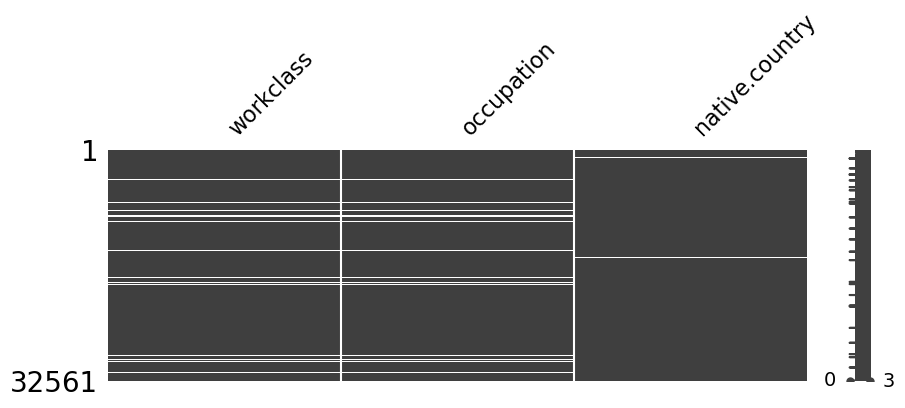

In [7]:
msn.matrix(df_adult[['workclass','occupation','native.country']],figsize=(10,3))

In [8]:
df_adult.describe(include=object).T #categorical

,count,unique,top,freq
workclass,30725,8,Private,22696
education,32561,16,HS-grad,10501
marital.status,32561,7,Married-civ-spouse,14976
occupation,30718,14,Prof-specialty,4140
relationship,32561,6,Husband,13193
race,32561,5,White,27816
sex,32561,2,Male,21790
native.country,31978,41,United-States,29170
income,32561,2,<=50K,24720


In [9]:
df_adult['workclass'].unique()

array([nan, 'Private', 'State-gov', 'Federal-gov', 'Self-emp-not-inc',
       'Self-emp-inc', 'Local-gov', 'Without-pay', 'Never-worked'],
      dtype=object)

In [10]:
df_adult['income'].unique()

array(['<=50K', '>50K'], dtype=object)

# preprocess scheme
1. one hot encoding : relationship,sex,race
1. binary encoding : workclass, marital status, occupation, native country

In [11]:
from category_encoders import BinaryEncoder
binary_encoder_pipeline = Pipeline([
    ('imputer',SimpleImputer(strategy='constant',fill_value='NC')),
    ('binary encoder',ce.BinaryEncoder())
])

transformer = ColumnTransformer([
    ('one hot encoder',OneHotEncoder(drop='first'),['relationship','race','sex']),
    ('binary encoder',binary_encoder_pipeline,['workclass','marital.status','occupation','native.country'])
],remainder='passthrough')


In [12]:
X = df_adult.drop(['fnlwgt','income','education'],axis=1)
y = np.where(df_adult['income']=='>50K',1,0)

In [13]:
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X,
    y,
    test_size=0.3,
    stratify = y,
    random_state=10
)

In [14]:
Counter(y)

Counter({0: 24720, 1: 7841})

In [15]:
# data transformation
X_train_val_preprocessed = transformer.fit_transform(X_train_val)
X_test_preprocessed = transformer.transform(X_test)

In [16]:
X_train_val_preprocessed = pd.DataFrame(X_train_val_preprocessed)
X_test_preprocessed = pd.DataFrame(X_test_preprocessed)
X_test_preprocessed

,0,1,2,3,4,5,6,7,8,9,...,22,23,24,25,26,27,28,29,30,31
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,23.0,9.0,0.0,0.0,40.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,56.0,4.0,0.0,0.0,50.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,55.0,13.0,0.0,0.0,55.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,36.0,9.0,0.0,0.0,40.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,19.0,9.0,0.0,0.0,30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9764,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,47.0,13.0,0.0,0.0,40.0
9765,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,27.0,10.0,0.0,0.0,60.0
9766,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,31.0,13.0,0.0,0.0,40.0
9767,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,58.0,5.0,0.0,0.0,40.0


In [17]:
# see the transformer
transformer

ColumnTransformer(remainder='passthrough',
                  transformers=[('one hot encoder', OneHotEncoder(drop='first'),
                                 ['relationship', 'race', 'sex']),
                                ('binary encoder',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(fill_value='NC',
                                                                strategy='constant')),
                                                 ('binary encoder',
                                                  BinaryEncoder())]),
                                 ['workclass', 'marital.status', 'occupation',
                                  'native.country'])])

In [18]:
transformer.transformers_

[('one hot encoder',
  OneHotEncoder(drop='first'),
  ['relationship', 'race', 'sex']),
 ('binary encoder',
  Pipeline(steps=[('imputer',
                   SimpleImputer(fill_value='NC', strategy='constant')),
                  ('binary encoder',
                   BinaryEncoder(cols=[0, 1, 2, 3],
                                 mapping=[{'col': 0,
                                           'mapping':     0_0  0_1  0_2  0_3
   1    0    0    0    1
   2    0    0    1    0
   3    0    0    1    1
   4    0    1    0    0
   5    0    1    0    1
   6    0    1    1    0
   7    0    1    1    1
   8    1    0    0    0
   9    1    0    0    1
  -1    0    0    0    0
  -2    0    0    0    0},
                                          {'col': 1,
                                           'mapping':     1_0  1_1  1_2
   1    0    0    1
   2    0    1    0
   3    0    1    1
   4    1    0    0
   5    1    0    1
   6    1    1    0
   7    1    1    1
  -1    0    0    0
  -2    

In [19]:
list1 = list(transformer.transformers_[0][1].get_feature_names_out())

In [20]:
transformer.transformers_[1][1][1]

BinaryEncoder(cols=[0, 1, 2, 3],
              mapping=[{'col': 0,
                        'mapping':     0_0  0_1  0_2  0_3
 1    0    0    0    1
 2    0    0    1    0
 3    0    0    1    1
 4    0    1    0    0
 5    0    1    0    1
 6    0    1    1    0
 7    0    1    1    1
 8    1    0    0    0
 9    1    0    0    1
-1    0    0    0    0
-2    0    0    0    0},
                       {'col': 1,
                        'mapping':     1_0  1_1  1_2
 1    0    0    1
 2    0    1    0
 3    0    1    1
 4    1    0    0
 5    1    0    1
 6    1    1    0
 7    1    1    1
-1    0    0    0
-2    0    0    0},
                       {'col': 2,
                        'mapping':      2_0  2_1  2_2  2_3
 1     0    0    0    1
 2     0    0    1    0
 3     0    0    1    1
 4     0    1    0    0
 5     0    1    0    1
 6     0    1    1    0
 7     0    1    1    1
 8     1    0    0    0
 9     1    0    0    1
 10    1    0    1    0
 11    1    0    1    1
 12    1    1    0    0
 13    1    1    0    1
 14    1    1    1    0
 15    1    1    1    1
-1     0    0    0    0
-2     0    0    0    0},
                       {'col': 3,
                        'mapping':      3_0  3_1  3_2...4  3_5
 1     0    0    0    0    0    1
 2     0    0    0    0    1    0
 3     0    0    0    0    1    1
 4     0    0    0    1    0    0
 5     0    0    0    1    0    1
 6     0    0    0    1    1    0
 7     0    0    0    1    1    1
 8     0    0    1    0    0    0
 9     0    0    1    0    0    1
 10    0    0    1    0    1    0
 11    0    0    1    0    1    1
 12    0    0    1    1    0    0
 13    0    0    1    1    0    1
 14    0    0    1    1    1    0
 15    0    0    1    1    1    1
 16    0    1    0    0    0    0
 17    0    1    0    0    0    1
 18    0    1    0    0    1    0
 19    0    1    0    0    1    1
 20    0    1    0    1    0    0
 21    0    1    0    1    0    1
 22    0    1    0    1    1    0
 23    0    1    0    1    1    1
 24    0    1    1    0    0    0
 25    0    1    1    0    0    1
 26    0    1    1    0    1    0
 27    0    1    1    0    1    1
 28    0    1    1    1    0    0
 29    0    1    1    1    0    1
 30    0    1    1    1    1    0
 31    0    1    1    1    1    1
 32    1    0    0    0    0    0
 33    1    0    0    0    0    1
 34    1    0    0    0    1    0
 35    1    0    0    0    1    1
 36    1    0    0    1    0    0
 37    1    0    0    1    0    1
 38    1    0    0    1    1    0
 39    1    0    0    1    1    1
 40    1    0    1    0    0    0
 41    1    0    1    0    0    1
 42    1    0    1    0    1    0
-1     0    0    0    0    0    0
-2     0    0    0    0    0    0}])

In [21]:
list2 = list(transformer.transformers_[1][1][1].get_feature_names_out())

In [22]:
features = list1 + list2 + ['age','education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
X_train_val_preprocessed.columns = features
X_test_preprocessed.columns = features
X_test_preprocessed

,relationship_Not-in-family,relationship_Other-relative,relationship_Own-child,relationship_Unmarried,relationship_Wife,race_Asian-Pac-Islander,race_Black,race_Other,race_White,sex_Male,...,3_1,3_2,3_3,3_4,3_5,age,education.num,capital.gain,capital.loss,hours.per.week
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,23.0,9.0,0.0,0.0,40.0
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,56.0,4.0,0.0,0.0,50.0
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,55.0,13.0,0.0,0.0,55.0
3,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,36.0,9.0,0.0,0.0,40.0
4,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,19.0,9.0,0.0,0.0,30.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9764,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,47.0,13.0,0.0,0.0,40.0
9765,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,27.0,10.0,0.0,0.0,60.0
9766,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,...,0.0,0.0,0.0,0.0,1.0,31.0,13.0,0.0,0.0,40.0
9767,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,...,0.0,0.0,0.0,0.0,1.0,58.0,5.0,0.0,0.0,40.0


In [23]:
# model fitting and test
tree = DecisionTreeClassifier(max_depth=3, random_state=10)
tree.fit(X_train_val_preprocessed,y_train_val)
y_pred = tree.predict(X_test_preprocessed)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.86      0.94      0.90      7417
           1       0.74      0.52      0.61      2352

    accuracy                           0.84      9769
   macro avg       0.80      0.73      0.76      9769
weighted avg       0.83      0.84      0.83      9769



In [24]:
# model properties
importance_table = pd.DataFrame(
    {'imp':tree.feature_importances_},index = features
)
importance_table

,imp
relationship_Not-in-family,0.000000
relationship_Other-relative,0.000000
relationship_Own-child,0.000000
relationship_Unmarried,0.000000
relationship_Wife,0.000000
race_Asian-Pac-Islander,0.000000
race_Black,0.000000
race_Other,0.000000
race_White,0.000000
sex_Male,0.000000


<Axes: >

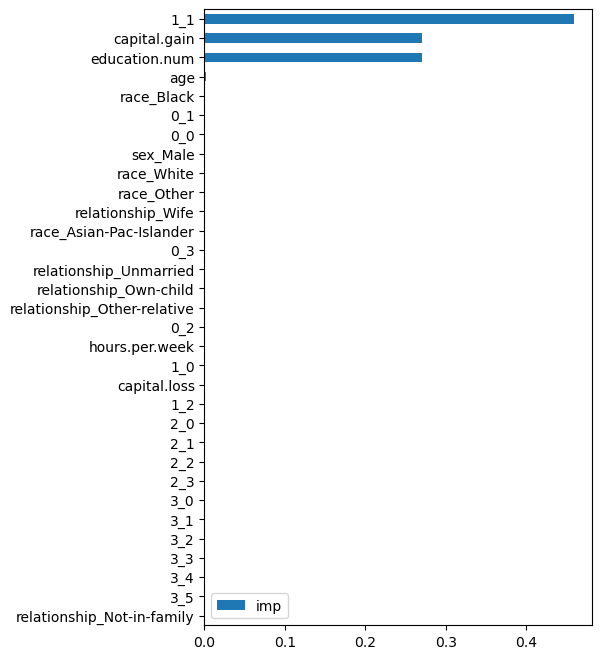

In [25]:
importance_table.sort_values(by='imp').plot(kind='barh',figsize=(5,8))

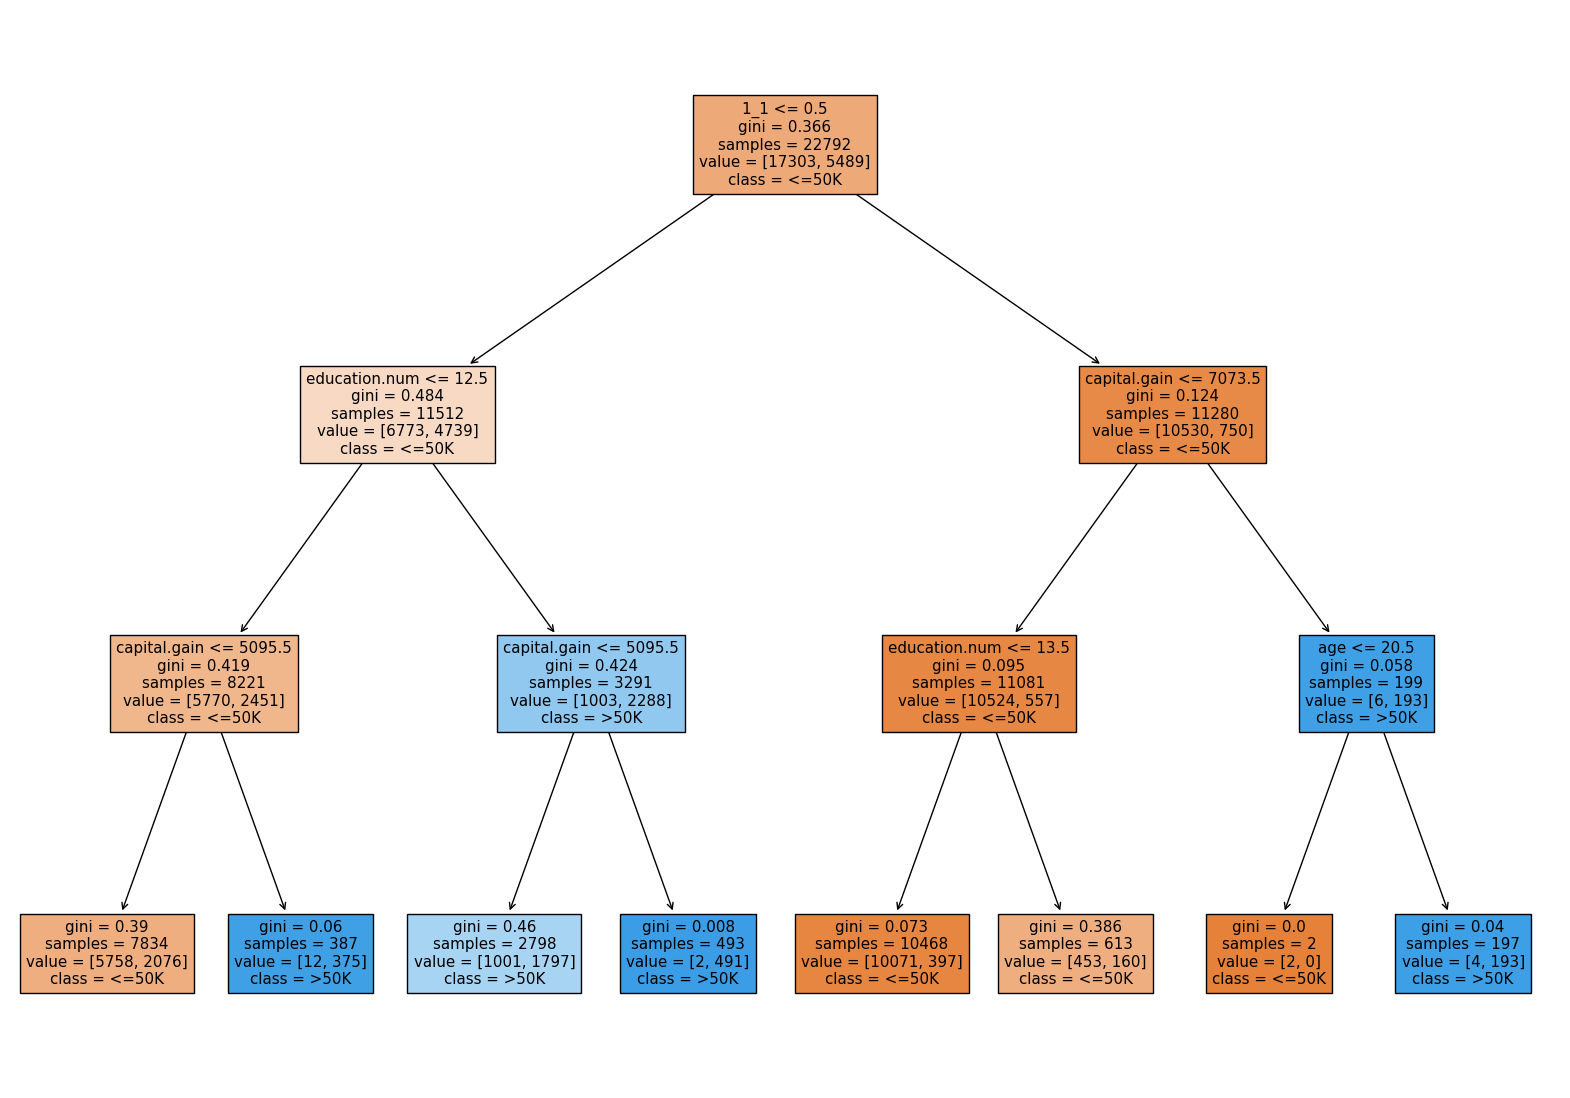

In [26]:
plt.figure(figsize=(20,14))
plot_tree(tree,feature_names=features,filled=True,class_names=['<=50K','>50K'])
plt.show()

In [27]:
# AdaBoost
tree = DecisionTreeClassifier(max_depth=3,random_state=10)
model = AdaBoostClassifier(
    tree,
    n_estimators=200,
    learning_rate=0.1,
    random_state=10
)
model.fit(X_train_val_preprocessed,y_train_val)
y_pred = model.predict(X_test_preprocessed)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.89      0.94      0.92      7417
           1       0.78      0.64      0.71      2352

    accuracy                           0.87      9769
   macro avg       0.84      0.79      0.81      9769
weighted avg       0.87      0.87      0.87      9769



In [36]:
# GradientBoost
model = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=10
)
model.fit(X_train_val_preprocessed,y_train_val)
y_pred = model.predict(X_test_preprocessed)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.89      0.95      0.92      7417
           1       0.79      0.63      0.70      2352

    accuracy                           0.87      9769
   macro avg       0.84      0.79      0.81      9769
weighted avg       0.87      0.87      0.87      9769



In [37]:
# model properties
importance_table = pd.DataFrame(
    {'imp':model.feature_importances_},index = features
)
importance_table.sort_values(by='imp',ascending=False)

,imp
1_1,0.294901
capital.gain,0.220534
education.num,0.192505
capital.loss,0.065087
age,0.064218
hours.per.week,0.044321
1_0,0.032189
2_0,0.028732
2_1,0.016940
relationship_Wife,0.007368


<Axes: >

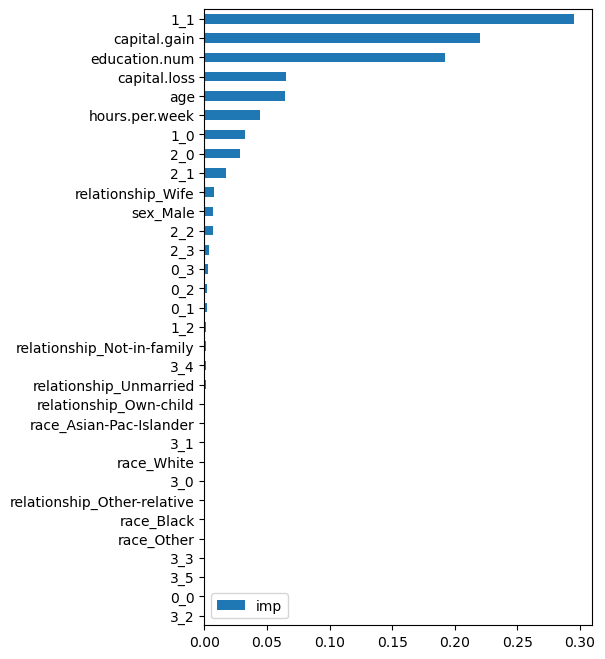

In [38]:
importance_table.sort_values(by='imp').plot(kind='barh',figsize=(5,8))

In [31]:
# XtremeGradientBoost
model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=10
)
model.fit(X_train_val_preprocessed,y_train_val)
y_pred = model.predict(X_test_preprocessed)
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.89      0.94      0.92      7417
           1       0.78      0.65      0.71      2352

    accuracy                           0.87      9769
   macro avg       0.84      0.79      0.81      9769
weighted avg       0.87      0.87      0.87      9769



In [32]:
# model properties
importance_table = pd.DataFrame(
    {'imp':model.feature_importances_},index = features
)
importance_table.sort_values(by='imp',ascending=False)

,imp
1_1,0.503284
1_0,0.060235
capital.gain,0.050852
education.num,0.048183
relationship_Own-child,0.045940
2_0,0.030950
capital.loss,0.024794
2_1,0.024483
1_2,0.023978
relationship_Wife,0.016323


<Axes: >

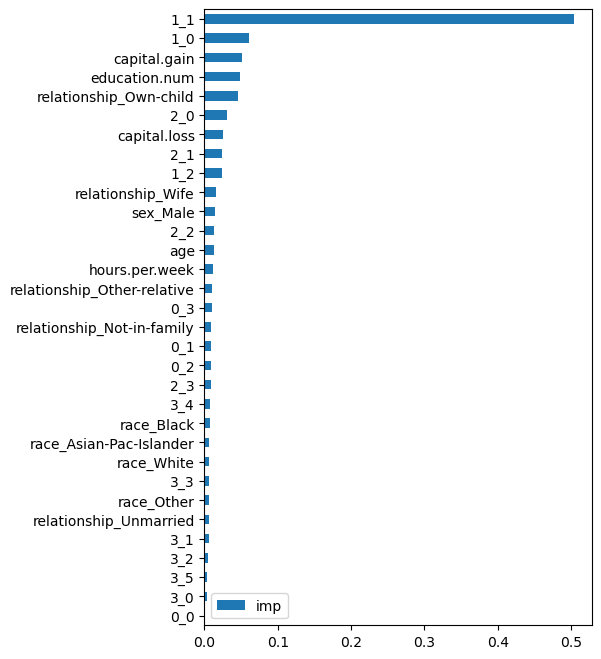

In [76]:
importance_table.sort_values(by='imp').plot(kind='barh',figsize=(5,8))

In [77]:
model_tree = DecisionTreeClassifier(max_depth=3,random_state=10)

model_ada = AdaBoostClassifier(
    tree,
    n_estimators=200,
    learning_rate=0.1,
    random_state=10
)

model_gbc = GradientBoostingClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=10
)

model_xgb = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    random_state=10
)

estimator = Pipeline(
    [('preprocess',transformer),
    ('clf',model)]
)

hyperparam_space = {
    'clf':[model_tree,model_ada,model_gbc,model_xgb]
}

skfold = StratifiedKFold(n_splits=5)

grid_search = GridSearchCV(
    estimator,
    param_grid = hyperparam_space,
    cv = skfold,
    scoring = 'f1',
    n_jobs = -1
)